# USPTO File Wrapper and Patent Drawings

The USPTO Patent File Wrapper API provides access not only to application metadata, but also to documents associated with a patent application.

In this workbook, we will use a known patent application to:

- retrieve its file-wrapper document information
- inspect the JSON returned by the API
- create a table of available documents
- identify documents that appear to contain drawings or figures
- download a drawing document as a PDF
- render and display drawing pages in Jupyter

This workbook begins where the introductory USPTO API workbook leaves off:

**patent application → file wrapper → document metadata → drawing document → image**

We will stop at retrieving and displaying the drawings. Analysis of the images can be done later with other computational tools.


## 1. Setup

We will use:

- `requests` to communicate with the USPTO API and download documents
- `yaml` to read the USPTO API key from `config.yml`
- `pandas` to inspect the list of documents
- `PyMuPDF` (`fitz`) to open PDF documents and render pages as images

The same `config.yml` used in the introductory USPTO workbook can be used here:

```yaml
api_key: YOUR_USPTO_API_KEY
```

If PyMuPDF is not installed in your environment, install it before continuing:

```python
%pip install pymupdf
```


In [1]:
import requests
import yaml
import pandas as pd
import fitz

from IPython.display import Image, display

with open("config.yml", "r") as f:
    config = yaml.safe_load(f)

API_KEY = config["uspto_api_key"]

BASE_URL = "https://api.uspto.gov/api/v1/patent/applications"

headers = {
    "X-API-KEY": API_KEY,
    "Accept": "application/json"
}


## 2. Choose a Patent Application

We will continue with application **15/694,515**, written without punctuation as `15694515` for the API.

Because the application number is stored in one variable, you can later replace it with another application and rerun the notebook.


In [2]:
APPLICATION_NUMBER = "15694515"


## 3. Retrieve the File-Wrapper Documents

The `/documents` endpoint returns information about documents associated with the application.


In [3]:
url = f"{BASE_URL}/{APPLICATION_NUMBER}/documents"

response = requests.get(url, headers=headers)
response.raise_for_status()

documents = response.json()


### Look at the JSON

As in the introductory API notebooks, inspect the response before transforming it.


In [4]:
documents


{'count': 63,
 'documentBag': [{'applicationNumberText': '15694515',
   'officialDate': '2023-06-27T00:00:00.000-0400',
   'documentIdentifier': 'LJE60W6EGREENX2',
   'documentCode': 'COCOUT',
   'documentCodeDescriptionText': 'Certificate of Correction - Post Issue Communication',
   'directionCategory': 'OUTGOING',
   'downloadOptionBag': [{'mimeTypeIdentifier': 'PDF',
     'downloadUrl': 'https://api.uspto.gov/api/v1/download/applications/15694515/LJE60W6EGREENX2.pdf',
     'pageTotalQuantity': 3}]},
  {'applicationNumberText': '15694515',
   'officialDate': '2023-05-31T17:21:24.000-0400',
   'documentIdentifier': 'LIC7PUGOXBLUEX2',
   'documentCode': 'COCIN',
   'documentCodeDescriptionText': 'Request for Certificate of Correction',
   'directionCategory': 'INCOMING',
   'downloadOptionBag': [{'mimeTypeIdentifier': 'PDF',
     'downloadUrl': 'https://api.uspto.gov/api/v1/download/applications/15694515/LIC7PUGOXBLUEX2.pdf',
     'pageTotalQuantity': 9}]},
  {'applicationNumberText':

In [5]:
documents.keys()


dict_keys(['count', 'documentBag'])

The document records are stored in `documentBag`.


In [6]:
documents.get("documentBag", [])[:2]


[{'applicationNumberText': '15694515',
  'officialDate': '2023-06-27T00:00:00.000-0400',
  'documentIdentifier': 'LJE60W6EGREENX2',
  'documentCode': 'COCOUT',
  'documentCodeDescriptionText': 'Certificate of Correction - Post Issue Communication',
  'directionCategory': 'OUTGOING',
  'downloadOptionBag': [{'mimeTypeIdentifier': 'PDF',
    'downloadUrl': 'https://api.uspto.gov/api/v1/download/applications/15694515/LJE60W6EGREENX2.pdf',
    'pageTotalQuantity': 3}]},
 {'applicationNumberText': '15694515',
  'officialDate': '2023-05-31T17:21:24.000-0400',
  'documentIdentifier': 'LIC7PUGOXBLUEX2',
  'documentCode': 'COCIN',
  'documentCodeDescriptionText': 'Request for Certificate of Correction',
  'directionCategory': 'INCOMING',
  'downloadOptionBag': [{'mimeTypeIdentifier': 'PDF',
    'downloadUrl': 'https://api.uspto.gov/api/v1/download/applications/15694515/LIC7PUGOXBLUEX2.pdf',
    'pageTotalQuantity': 9}]}]

## 4. Build a Table of Available Documents

A file wrapper can contain many documents. To make the response easier to explore, we will select a few useful fields from each document.

For each document, we will keep:

- official date
- document code
- description
- direction
- document identifier
- PDF page count, when available
- PDF download URL, when available


In [7]:
doc_list = []

for doc in documents.get("documentBag", []):
    pdf_options = [
        option for option in doc.get("downloadOptionBag", [])
        if option.get("mimeTypeIdentifier") == "PDF"
    ]

    doc_list.append({
        "date": doc.get("officialDate"),
        "code": doc.get("documentCode"),
        "description": doc.get("documentCodeDescriptionText"),
        "direction": doc.get("directionCategory"),
        "document_id": doc.get("documentIdentifier"),
        "pages": pdf_options[0].get("pageTotalQuantity") if pdf_options else None,
        "pdf_url": pdf_options[0].get("downloadUrl") if pdf_options else None
    })

docs_df = pd.DataFrame(doc_list)

docs_df


,date,code,description,direction,document_id,pages,pdf_url
0,2023-06-27T00:00:00.000-0400,COCOUT,Certificate of Correction - Post Issue Communi...,OUTGOING,LJE60W6EGREENX2,3,https://api.uspto.gov/api/v1/download/applicat...
1,2023-05-31T17:21:24.000-0400,COCIN,Request for Certificate of Correction,INCOMING,LIC7PUGOXBLUEX2,9,https://api.uspto.gov/api/v1/download/applicat...
2,2023-05-31T17:21:24.000-0400,COCIN,Request for Certificate of Correction,INCOMING,LIC7PUGPXBLUEX2,7,https://api.uspto.gov/api/v1/download/applicat...
3,2023-05-31T17:21:24.000-0400,N417,Electronic Filing System Acknowledgment Receipt,OUTGOING,LIC7PUGQXBLUEX2,2,https://api.uspto.gov/api/v1/download/applicat...
4,2019-05-29T15:22:15.000-0400,ISSUE.NTF,Issue Notification,OUTGOING,JW9M9CCURXEAPX0,1,https://api.uspto.gov/api/v1/download/applicat...
...,...,...,...,...,...,...,...
58,2017-09-01T00:00:00.000-0400,OATH,Oath or Declaration filed,INCOMING,J72H0163RXEAPX0,2,https://api.uspto.gov/api/v1/download/applicat...
59,2017-09-01T00:00:00.000-0400,ADS,Application Data Sheet,INCOMING,J72H0164RXEAPX0,9,https://api.uspto.gov/api/v1/download/applicat...
60,2017-09-01T00:00:00.000-0400,DRW,Drawings-only black and white line drawings,INCOMING,J72H0165RXEAPX0,4,https://api.uspto.gov/api/v1/download/applicat...
61,2017-09-01T00:00:00.000-0400,WFEE,Fee Worksheet (SB06),INTERNAL,J72H0166RXEAPX0,2,https://api.uspto.gov/api/v1/download/applicat...


The DataFrame gives us a compact view of the application's file wrapper. You can sort, filter, or search this table just as you would other pandas data.


In [8]:
docs_df[["date", "code", "description", "pages"]].head(20)


,date,code,description,pages
0,2023-06-27T00:00:00.000-0400,COCOUT,Certificate of Correction - Post Issue Communi...,3
1,2023-05-31T17:21:24.000-0400,COCIN,Request for Certificate of Correction,9
2,2023-05-31T17:21:24.000-0400,COCIN,Request for Certificate of Correction,7
3,2023-05-31T17:21:24.000-0400,N417,Electronic Filing System Acknowledgment Receipt,2
4,2019-05-29T15:22:15.000-0400,ISSUE.NTF,Issue Notification,1
5,2019-04-18T13:20:06.000-0400,LET.,Miscellaneous Incoming Letter,3
6,2019-04-18T13:20:06.000-0400,IFEE,Issue Fee Payment (PTO-85B),1
7,2019-04-18T13:20:06.000-0400,WFEE,Fee Worksheet (SB06),2
8,2019-04-18T13:20:06.000-0400,N417,Electronic Filing System Acknowledgment Receipt,2
9,2019-04-16T17:27:22.000-0400,DRW,Drawings-only black and white line drawings,3


## 5. Find Drawing Documents

For this introductory example, we will search the document descriptions for words such as `draw`, `figure`, or `fig.`.

This is intentionally a simple filter. Patent applications and their file wrappers vary, so other applications may use different document descriptions.


In [9]:
drawings_df = docs_df[
    docs_df["description"].str.contains(
        r"draw|figure|fig\.",
        case=False,
        na=False,
        regex=True
    )
].copy()

drawings_df


,date,code,description,direction,document_id,pages,pdf_url
9,2019-04-16T17:27:22.000-0400,DRW,Drawings-only black and white line drawings,INCOMING,JUKASMHBRXEAPX3,3,https://api.uspto.gov/api/v1/download/applicat...
60,2017-09-01T00:00:00.000-0400,DRW,Drawings-only black and white line drawings,INCOMING,J72H0165RXEAPX0,4,https://api.uspto.gov/api/v1/download/applicat...


If multiple drawing-related documents are returned, inspect the table and decide which one you want to retrieve.

For the workshop example, we will use the first drawing-related document that has a PDF download URL.


In [10]:
downloadable_drawings = drawings_df.dropna(subset=["pdf_url"])

downloadable_drawings[["date", "code", "description", "pages"]]


,date,code,description,pages
9,2019-04-16T17:27:22.000-0400,DRW,Drawings-only black and white line drawings,3
60,2017-09-01T00:00:00.000-0400,DRW,Drawings-only black and white line drawings,4


## 6. Download a Drawing Document

Select the first downloadable drawing document and save its PDF locally.


In [11]:
row = downloadable_drawings.iloc[0]

print("Code:", row["code"])
print("Description:", row["description"])
print("Pages:", row["pages"])

pdf_url = row["pdf_url"]

pdf_response = requests.get(pdf_url, headers=headers)
pdf_response.raise_for_status()

filename = f"{APPLICATION_NUMBER}_drawings.pdf"

with open(filename, "wb") as f:
    f.write(pdf_response.content)

print("Saved:", filename)


Code: DRW
Description: Drawings-only black and white line drawings
Pages: 3
Saved: 15694515_drawings.pdf


## 7. Open the PDF and Display a Drawing Page

PyMuPDF can open the downloaded PDF and render a page as an image.


In [12]:
pdf = fitz.open(filename)

print("Pages in downloaded PDF:", len(pdf))


Pages in downloaded PDF: 3


Display the first page.


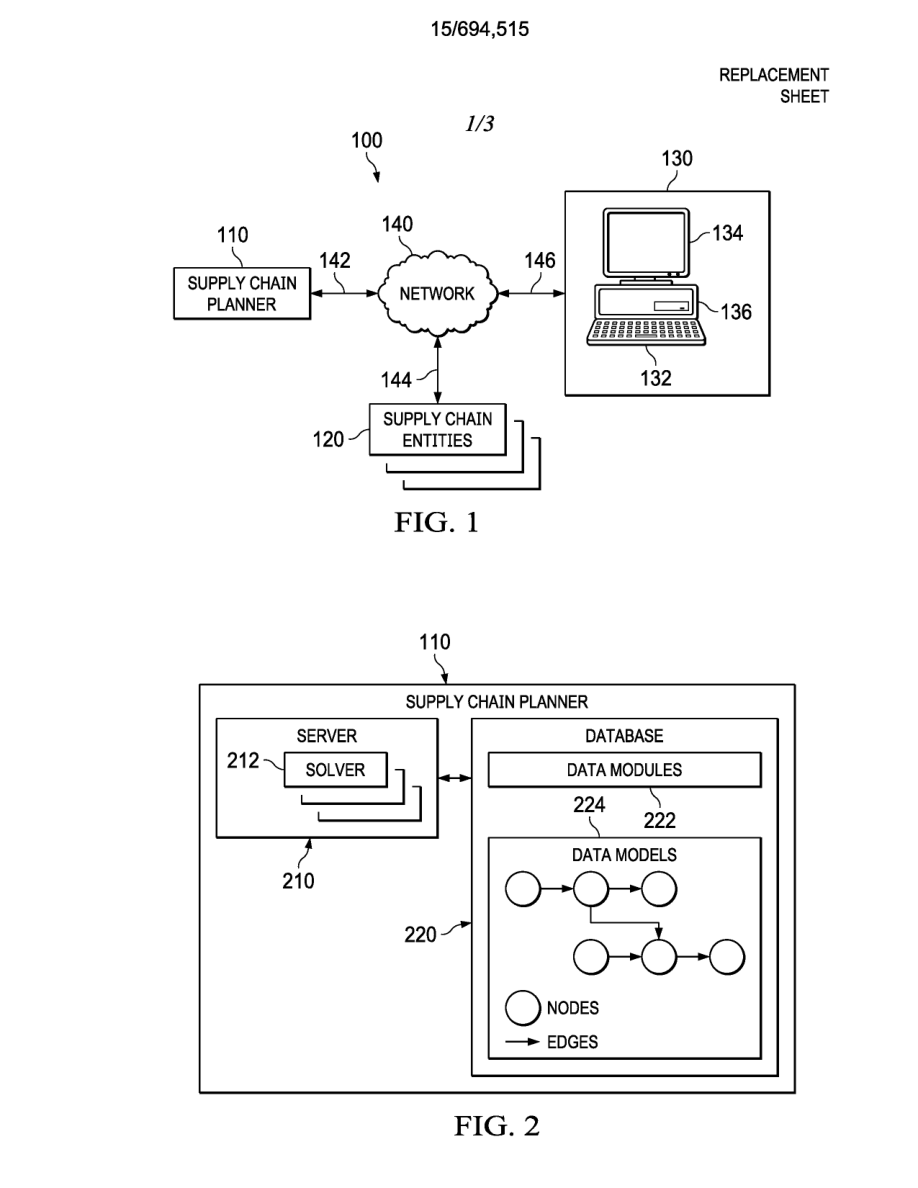

In [13]:
PAGE_NUMBER = 0

page = pdf[PAGE_NUMBER]
pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))

display(Image(data=pix.tobytes("png")))


### Look at another page

Change `PAGE_NUMBER` to inspect another page in the drawing document. Python uses zero-based indexing, so page `0` is the first page, page `1` is the second, and so on.

For example:

```python
PAGE_NUMBER = 1
```

Make sure the page number is smaller than the number printed by `len(pdf)`.


## 8. Optional: Display Several Drawing Pages

For a short document, it can be useful to display the first few pages together.


Page 1


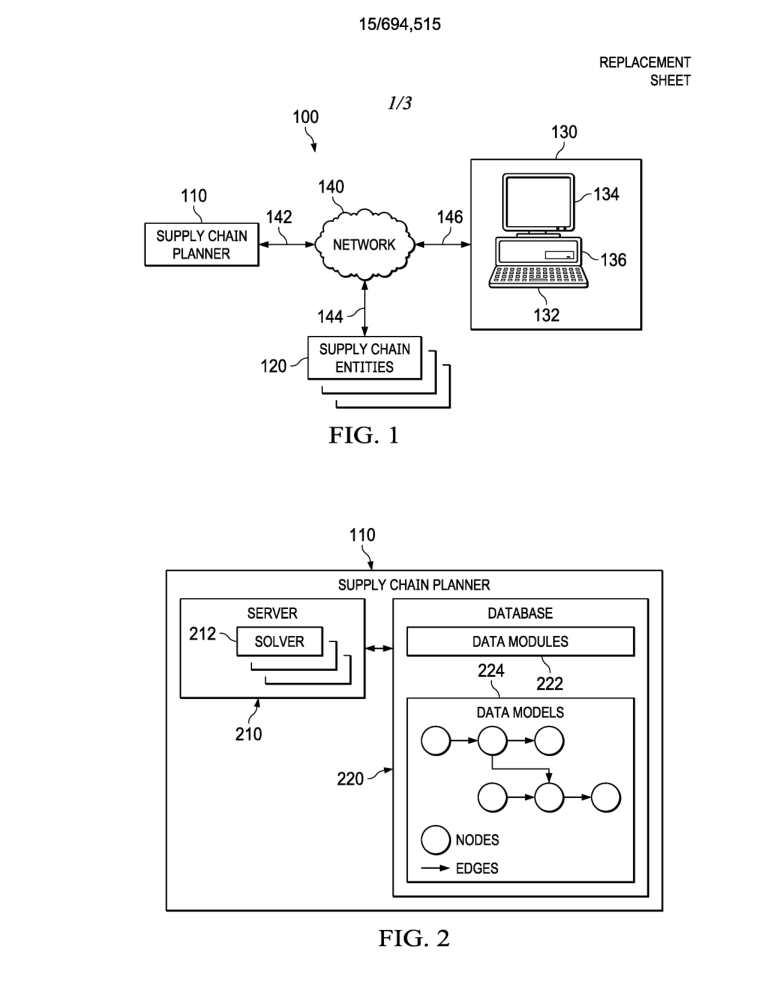

Page 2


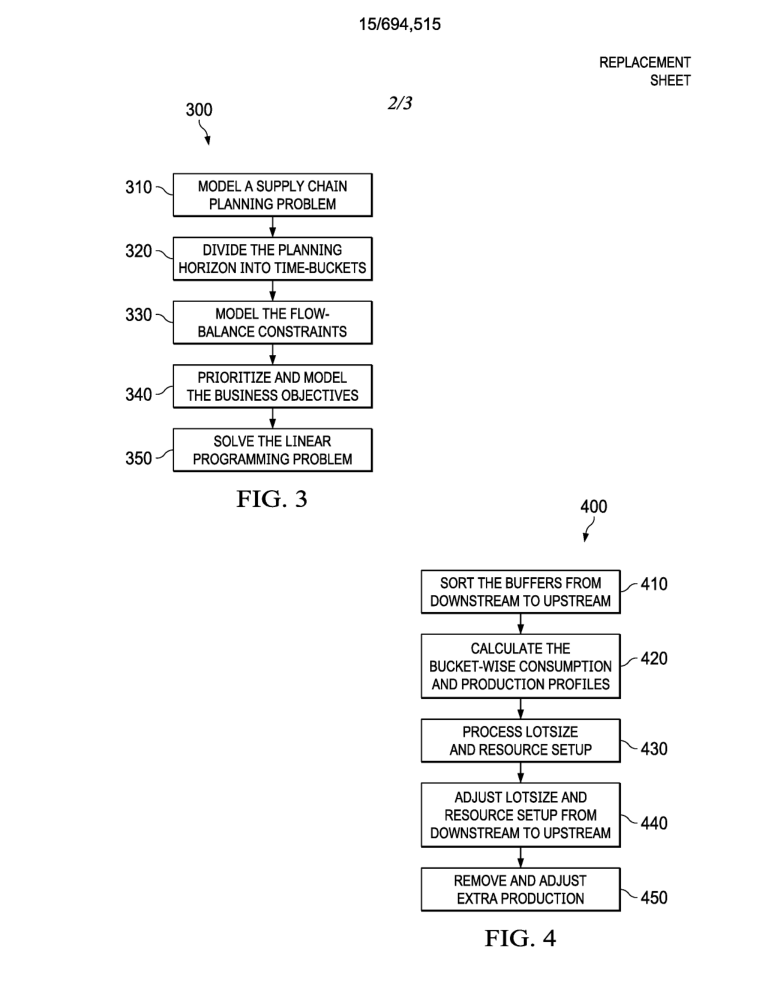

Page 3


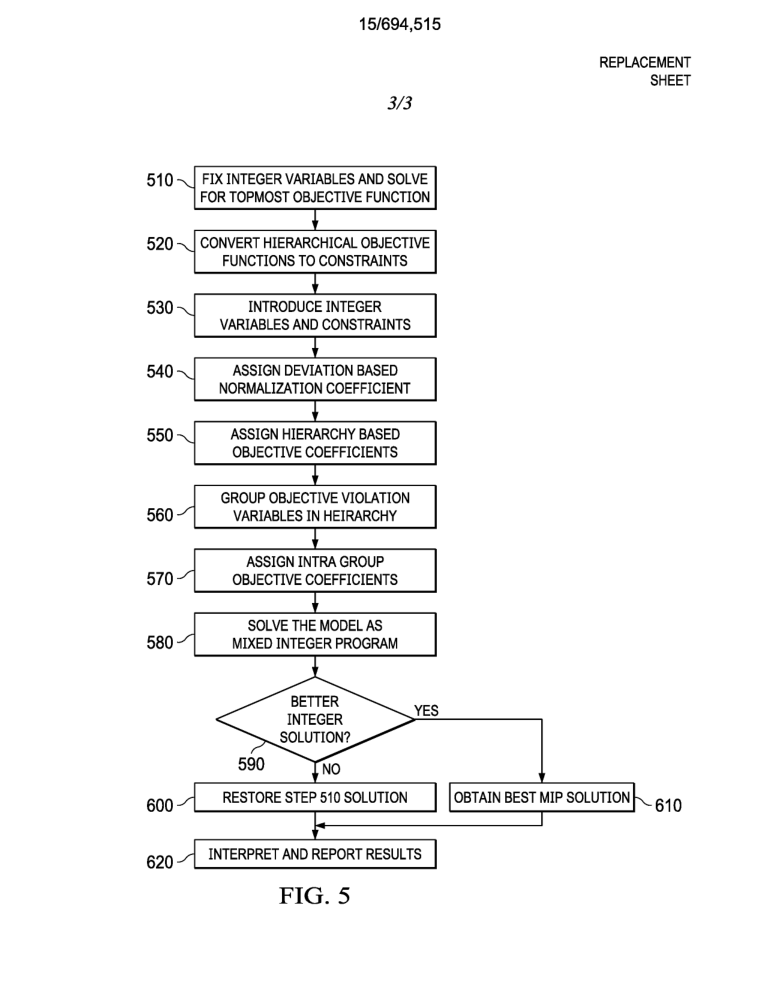

In [14]:
pages_to_show = min(3, len(pdf))

for page_number in range(pages_to_show):
    print(f"Page {page_number + 1}")

    page = pdf[page_number]
    pix = page.get_pixmap(matrix=fitz.Matrix(1.25, 1.25))

    display(Image(data=pix.tobytes("png")))


## 9. Try Another Patent Application

Once the workflow works, replace:

```python
APPLICATION_NUMBER = "15694515"
```

with another USPTO application number and rerun the notebook.

Questions to explore:

1. What kinds of documents are present in the file wrapper?
2. Are drawing documents available?
3. How many pages do the drawing documents contain?
4. Do different applications use different document descriptions or codes?
5. What other kinds of file-wrapper documents might be useful for research?


## 10. What We Did

In this workbook, we moved from structured patent information to the underlying documents associated with an application:

**application number → document API → JSON → document table → drawing document → PDF → rendered image**

This is a useful boundary between patent-data retrieval and document analysis.

The USPTO API helped us locate and retrieve the documents. Once a drawing has been rendered as an image, other computational methods can be used to analyze its contents. That will be a separate step rather than part of this workbook.
